<a href="https://colab.research.google.com/github/yuvasrisugu2008-maker/ITA0515--COMPUTER-VISION/blob/main/exp%2027.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Libraries imported successfully!
OpenCV Version: 5.0.0
CascadeClassifier available: False


Saving image.jpeg to image (11).jpeg
Image uploaded: image (11).jpeg


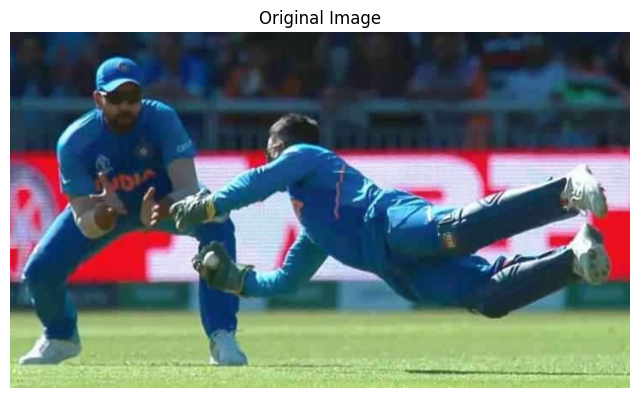

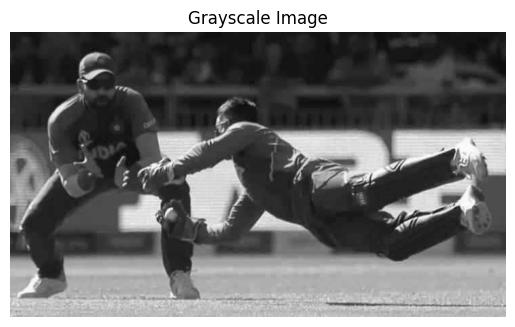

AttributeError: module 'cv2' has no attribute 'CascadeClassifier'

In [37]:
import cv2
import matplotlib.pyplot as plt
from google.colab import files

print("Libraries imported successfully!")
print("OpenCV Version:", cv2.__version__)
print("CascadeClassifier available:", hasattr(cv2, "CascadeClassifier"))
uploaded = files.upload()

filename = list(uploaded.keys())[0]

print("Image uploaded:", filename)
# Read uploaded image
img = cv2.imread(filename)

if img is None:
    raise ValueError("Unable to read the uploaded image.")

# Convert BGR to RGB
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Display original image
plt.figure(figsize=(8, 6))
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)

if face_cascade.empty():
    raise ValueError("Face detection model not loaded.")

print("Haar Cascade model loaded successfully!")
faces = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

print("Number of faces detected:", len(faces))
output = img.copy()

for (x, y, w, h) in faces:

    cv2.rectangle(
        output,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

    cv2.putText(
        output,
        "Face",
        (x, max(y - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 0),
        2
    )

print("Face detection completed!")
result = cv2.cvtColor(output, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 7))
plt.imshow(result)
plt.title("Face Detection Result")
plt.axis("off")
plt.show()